# zf1 — Measure

`metadata.hera.policy` — scientific record: append new cells; never edit or
delete executed ones. (Who *executes* a measure cell is set by the session
mode — see the brief.)

Confirm each `# <-- verify` (rig: addresses) and `# <-- validate` (device:
operating limits, wiring) line at bring-up. Cells marked **PATTERN** /
**PROPOSAL** carry `<PLACEHOLDER>` values — review before running.

## Setup

In [1]:
import os
import time

import numpy as np
import scipy.constants as cst

import qcodes
from qcodes import validators
from qcodes.instrument_drivers.stanford_research import SR830, SR860
from qcodes.instrument_drivers.Keithley import Keithley2400
from qcodes.instrument_drivers.american_magnetics import AMIModel430

import sweep

from hera.analysis import GateCalibration, field_invB

from sharpelab_nb.constants import TOPLOADER
from sharpelab_nb.thermometry import temperature_from_logfile
from sharpelab_nb.drivers import SRS_DC205

In [2]:
main_dir = os.getcwd()
sweep.set_basedir(os.path.join(main_dir, "data"))
main_dir

'C:\\Users\\toploader\\measurements\\aaron\\20260622-zf1'

# Connect Instruments

## Magnet

In [3]:
MAGNET_ADDR = "TCPIP0::192.168.0.101::7180::SOCKET"  # <-- verify address
magnet = AMIModel430("magnet", address=MAGNET_ADDR)
# Field in Tesla; magnet.field() is the MEASURED readback (coil constant
# 0.116783 T/A is configured on the unit). magnet.field(target) BLOCKS until
# the supply reports holding; a kernel interrupt does NOT stop the ramp.
magnet.field()

Connected to: AMERICAN MAGNETICS INC. 430 (serial:430-11-044, firmware:2.65) in 1.06s


-4.0625e-05

## Thermometry (file-based) + sample heater

Kernel temperature reads are **file-based**, not GPIB — the AVS bridge workers
own the bridges and write the logfiles. `temperature` is the loaded probe's
mixing chamber; the logfile path is **probe-dependent** (Probe1 = straight,
Probe2 = rotator). The sample heater is an **open-loop** Keithley voltage
source — set `heater.volt`, settle, then read T back from `temperature()`.

In [4]:
# Probe MC (sample T) — point at the LOADED probe (Probe1 straight / Probe2 rotator)
temperature = temperature_from_logfile(
    "T", r"C:\Users\toploader\temperature_logs\Probe2_MixingCh_low.txt")  # <-- verify probe
fridge_temperature = temperature_from_logfile("T_fridge", TOPLOADER.temp_logfiles["T_fridge"])
mag_temperature = temperature_from_logfile("T_magnet", TOPLOADER.temp_logfiles["T_magnet"])
print("probe MC:", temperature(), "K")

# Sample-stage heater — open-loop voltage drive (V->T is per-cooldown; device card)
heater = Keithley2400("heater", "GPIB4::12::INSTR")  # <-- verify address
heater.mode.set("VOLT")
heater.volt.step = 0.005

probe MC: 0.0337 K
Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:1299232, firmware:C30   Mar 17 2006 09:29:29/A02  /K/J) in 0.08s


## Lock-ins

In [5]:
sr830_1 = SR830("sr830_1", "GPIB0::8::INSTR")  # <-- verify — current channel (Ithaco 1211 preamp output)
sr830_2 = SR830("sr830_2", "GPIB0::9::INSTR")  # <-- verify
sr830_3 = SR830("sr830_3", "GPIB0::4::INSTR")  # <-- verify
sr830_4 = SR830("sr830_4", "GPIB0::1::INSTR")  # <-- verify
sr830_5 = SR830("sr830_5", "GPIB0::5::INSTR")  # <-- verify
sr830_6 = SR830("sr830_6", "GPIB0::6::INSTR")  # <-- verify
sr830_7 = SR830("sr830_7", "GPIB0::7::INSTR")  # <-- verify
# sr830_8 = SR860("sr830_8", "TCPIP::192.168.0.107::inst0::INSTR")  # <-- verify — SR860; enable if used

C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr830_1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_2 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages

Connected to: Stanford_Research_Systems SR830 (serial:s/n45469, firmware:ver1.07) in 0.13s
Connected to: Stanford_Research_Systems SR830 (serial:s/n45595, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n45471, firmware:ver1.07) in 0.10s


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_4 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr830_4 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_5 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages

Connected to: Stanford_Research_Systems SR830 (serial:s/n43722, firmware:ver1.07) in 0.11s
Connected to: Stanford_Research_Systems SR830 (serial:s/n45470, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n43721, firmware:ver1.07) in 0.11s
Connected to: Stanford_Research_Systems SR830 (serial:s/n41621, firmware:ver1.07) in 0.09s


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_6 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr830_6 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_7 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages

## Keithleys (gates)

In [6]:
# Gate Keithleys are role-named on this rig (k_tg/k_bg drive top/back gates),
# so recipes' k_tg / k_bg resolve directly. The third Keithley's role is
# per-insert (Si gate, or a probe-specific winding). Defaults: rangev 21,
# rangei 1uA, compliance 10 nA / 20 V, step 5 mV.
def _setup_k2400(k):
    # k.mode.set("VOLT")
    # k.rangev.set(21)
    # k.rangei.set(1e-6)
    # k.compliancev.set(20)
    # k.compliancei.set(1e-8)
    k.volt.step = 0.005
    return k

k_tg  = _setup_k2400(Keithley2400("k_tg",  "GPIB4::9::INSTR"))   # <-- verify — top gate
k_bg  = _setup_k2400(Keithley2400("k_bg",  "GPIB4::10::INSTR"))  # <-- verify — back gate
k_tg2 = _setup_k2400(Keithley2400("k_tg2", "GPIB4::11::INSTR"))  # <-- verify — third Keithley (per-insert role)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:4028439, firmware:C32   Oct  4 2010 14:20:11/A02  /T/K) in 0.03s
Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:4028442, firmware:C32   Oct  4 2010 14:20:11/A02  /T/K) in 0.03s
Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:4028489, firmware:C32   Oct  4 2010 14:20:11/A02  /T/K) in 0.02s


## DC205 (DC current bias)

On the toploader, gates are Keithleys; the DC205s are **DC current-bias**
sources (through a 100 MΩ series resistor — see the device card). Set
`volt -> 0` before reconfiguring or ending a measurement.

In [7]:
dc205_1 = SRS_DC205("dc205_1", "ASRL6::INSTR")  # <-- verify address — DC current bias
dc205_1.volt = dc205_1.voltage
dc205_1.volt.step = 0.005

dc205_3 = SRS_DC205("dc205_3", "ASRL7::INSTR")  # <-- verify address — second DC205
dc205_3.volt = dc205_3.voltage
dc205_3.volt.step = 0.005

Connected to: Stanford_Research_Systems DC205 (serial:s/n20500516, firmware:ver1.80) in 0.02s
Connected to: Stanford_Research_Systems DC205 (serial:s/n20500513, firmware:ver1.80) in 0.03s


# SAFETIES

Run immediately after instrument bring-up, before any sweep.

In [8]:
# slot: gate-validators — operating limits from the device card's gate-
# operating-limits table; commit EXACTLY the card numbers. Each value
# `# <-- validate`.
TG_MIN, TG_MAX = -7.0, +6.0   # top gate (k_tg), V    # <-- validate
BG_MIN, BG_MAX = -4.0, +4.2   # back gate (k_bg), V    # <-- validate
k_tg.volt.vals = validators.Numbers(TG_MIN, TG_MAX)
k_bg.volt.vals = validators.Numbers(BG_MIN, BG_MAX)

# Limit lists for sanitize_tg_bg()
tg_lims, bg_lims = [TG_MIN, TG_MAX], [BG_MIN, BG_MAX]

# Session field cap — machine-enforced: magnet.field is a qcodes Parameter, so
# this validator rejects magnet.field(target) with |B| > cap before any
# hardware traffic. Driver backstop: |B| <= COIL? x current_limit (~9 T) on the
# AMI430 unit.
B_SESSION_CAP = 0.1  # Tesla (100 mT)    # <-- validate (session cap from card/brief)
magnet.field.vals = validators.Numbers(-B_SESSION_CAP, B_SESSION_CAP)

# Sample-heater ceiling for sustained runs (V, not T — open-loop drive).
HEATER_V_MAX = 6.5  # V    # <-- validate
heater.volt.vals = validators.Numbers(0, HEATER_V_MAX)

# DC current-bias range (SRS DC205 hardware: +/-15 V -> +/-150 nA at 100 MOhm).
dc205_1.volt.vals = validators.Numbers(-15, 15)

# Helpers

In [9]:
def spoints(a, b, c):
    return np.linspace(a, b, c)


def sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims):
    """
    Given a list of tg and bg voltages, removes any points which are outside tg_lims and bg_lims
    """
    vtg_new_vec = []
    vbg_new_vec = []
    for ind in range(len(vtg_vec)):
        vtg, vbg = vtg_vec[ind], vbg_vec[ind]
        if vtg < tg_lims[0] or vtg > tg_lims[1] or vbg < bg_lims[0] or vbg > bg_lims[1]:
            pass
        else:
            vtg_new_vec.append(vtg)
            vbg_new_vec.append(vbg)
    return np.array(vtg_new_vec), np.array(vbg_new_vec)

In [10]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 23.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 20e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

# Measurement config

In [11]:
# slot: meas-config — channel/contact assignments + gains from the device
# card's Measurement setup (current channel + gain, provided contact
# configuration). Each value `# <-- validate`. Toploader contacts are wired
# DIRECT (no QSwitch) — name the contact pair per channel. Always set 'comment'
# per run — structured, current, no inherited text.
meas_config = {
    "sr1": "5-4",     "sr1_gain": -1e6,   # current channel (Ithaco 1211)    # <-- validate
    "sr2": "5-4",     "sr2_gain": 1e2,    # 2-terminal    # <-- validate
    "sr3": "30-31",   "sr3_gain": 1e2,    # 4-terminal longitudinal    # <-- validate
    "bias_resistor": 1e8,
    "bias_voltage_1": sr830_1.amplitude(),
    "lockin_freq_1": sr830_1.frequency(),
    "comment": "<SET PER RUN>",
}

# HERA — session start (2026-06-22)

## HERA — Gate C: cheap liveness check (`gate-current-sanity-check`, first-session branch)

Bring-up is green: setup ran in-kernel (probe MC **33.7 mK**, all instruments connected), SAFETIES committed (cell 16, exec [8]) with card-exact validators — `k_tg ∈ (−7,+6)`, `k_bg ∈ (−4,+4.2)`, **|B|≤0.1 T** on `magnet.field` — and `magnet.field()` reads **−0.04 mT** (≈0). [VERIFY] all green.

This is the **liveness-only** branch: the gate operating limits are *provided* (device card) and *already committed* as validators, and the range-finding family is blocklisted this session — so no iterate-then-bless loop, no Cell B. One small TG excursion (0 → **+1 V**, deep inside the +6 V validator) with `k_bg` parked at 0, watching three things:

- **Lock-in X** on `sr1`(5-4, current), `sr2`(5-4, 2T), `sr3`(30-31, **4T longitudinal Rxx**) — nonzero, smooth → device alive, contacts read clean, the 4T channel is live.
- **`k_tg.curr`** (active gate) — stays in pA → no leakage at the operating point.
- **`k_bg.curr`** (parked) — at floor → no cross-gate path.

`nplci=10` on the gate-current channels for pA-floor readback (reset to 1 in the `finally`). AC drive set to **0.1 V → ~1 nA** at the device (device card, 100 MΩ bias R). Magnet untouched — the Step-1 survey map is still pristine-field.

**Precondition asserts** at top (state this cell assumes but does not set): base T, B≈0. Gates are parked by the cell, so their start value only costs ramp time.

**Cost:** ~1.5–2 min (51 pts × ~1 s + the 5 mV/step ramps). **Read after it lands:** if all three reads are clean I advance to the Step-1 axis-aligned survey gatemap (does double duty as the cap-ratio calibration); any flat/saturated channel or nA gate current stops me per the failure-mode catalog.


probe MC T = 33.7 mK   (expect base, mK range)
magnet B   = -0.007 mT  (expect ~0)
k_tg.volt  = +0.0000 V    k_bg.volt = +0.0000 V    (cell parks both to 0)
2026-06-22 16:47:50,573 [INFO] Ramping k_bg_volt: 0.0 -> 0
2026-06-22 16:47:51,093 [INFO] Ramping k_tg_volt: 0.0 -> 0
2026-06-22 16:47:51,115 [INFO] Starting sweep with ID 0
2026-06-22 16:47:51,116 [INFO] Minimum duration 0h 0m 51s


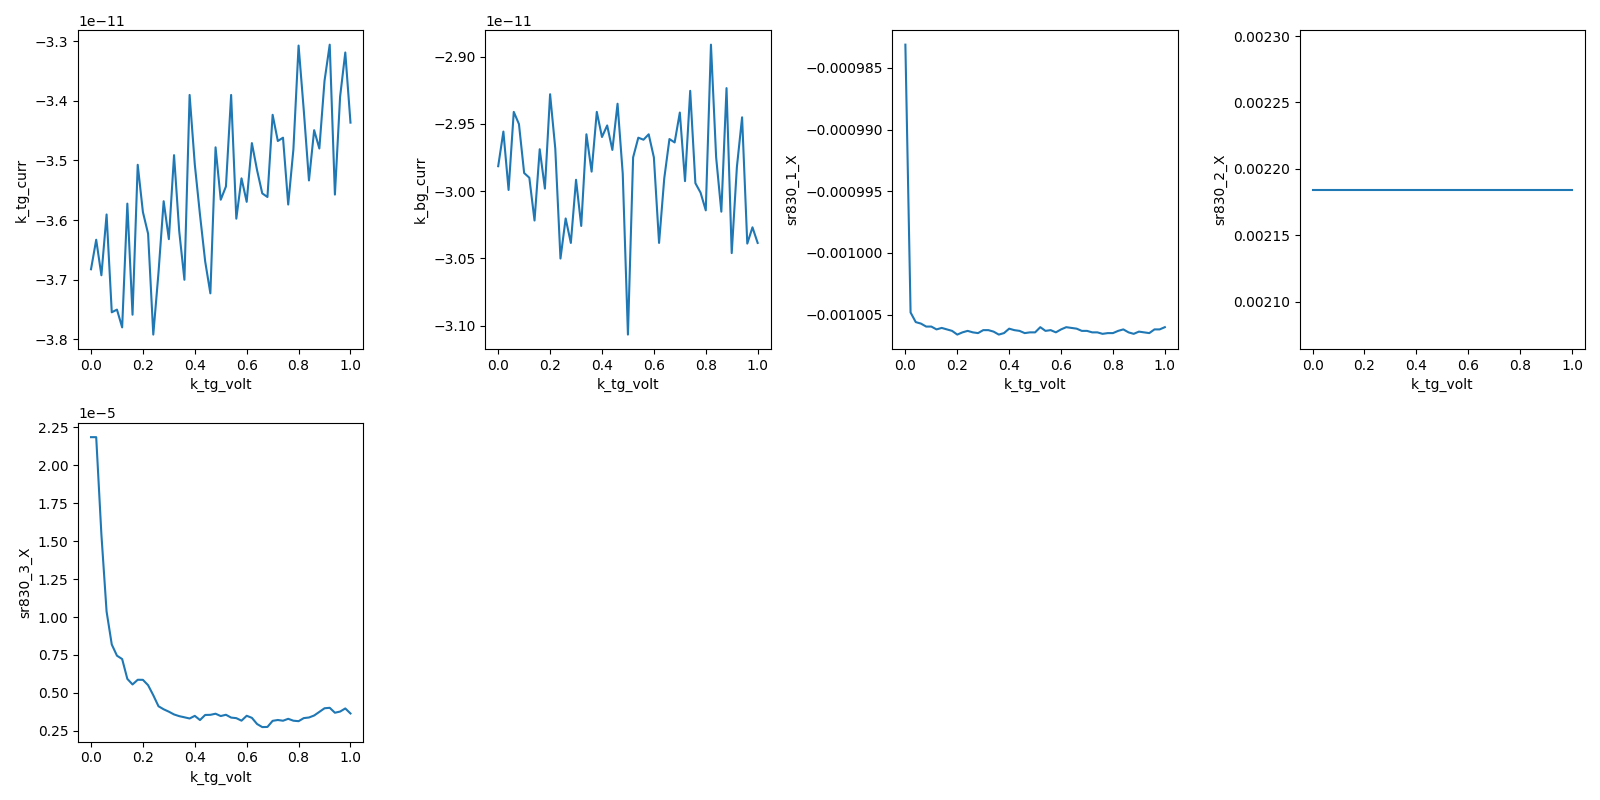

2026-06-22 16:49:36,774 [INFO] Completed in 0h 1m 45s
2026-06-22 16:49:36,774 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260622-zf1\data\0\data.tsv.gz
2026-06-22 16:49:37,285 [INFO] Ramping k_tg_volt: 1.0 -> 0


In [12]:
# === Gate C — cheap liveness check (first-session branch, gate-current-sanity-check) ===
# Confirms: (1) device passes lock-in current, (2) provided contacts read clean,
# (3) the 4T longitudinal Rxx channel (sr3 = 30-31) is live, (4) no gate leakage at
# the operating point. Validators are ALREADY committed from the device card
# (SAFETIES, cell 16) -> liveness only, NOT the iterate-then-bless range loop.

# --- precondition reads (silent state this cell assumes but does not set) ---
_T = temperature()
_B = magnet.field()
print(f"probe MC T = {_T*1e3:.1f} mK   (expect base, mK range)")
print(f"magnet B   = {_B*1e3:+.3f} mT  (expect ~0)")
print(f"k_tg.volt  = {k_tg.volt():+.4f} V    k_bg.volt = {k_bg.volt():+.4f} V    (cell parks both to 0)")
assert _T < 0.060, f"T={_T*1e3:.1f} mK not at base"
assert abs(_B) < 0.005, f"|B|={_B*1e3:.2f} mT not ~0"

# AC sense drive -> ~1 nA at the device (device card: 0.1 V over the 100 MOhm bias R)
sr830_1.amplitude(0.1)

# nplci=10 on the gate-current channels for pA-floor leakage readback; reset to 1 in finally.
k_tg.nplci(10)
k_bg.nplci(10)

meas_config["comment"] = "Gate C liveness: k_tg 0->+1V, k_bg=0, 1nA AC, B=0"

gate       = k_tg
v_endpoint = +1.0        # small excursion, deep inside the +6 V validator
n_pts      = 51
delay      = 1           # s
lockins    = [sr830_1, sr830_2, sr830_3]   # current + 2T + 4T-longitudinal, per meas_config

s = sweep.AsyncStation(meas_config)
s.add_comment('gate-current-sanity-check')
s.add_comment('branch: cheap-liveness (validators pre-committed from device card)')
s.add_comment(f'gate: {gate.name}  leg: 0 -> {v_endpoint:+g} V  (k_bg parked 0)')

s.ramp(k_bg.volt, 0)
s.ramp(k_tg.volt, 0)

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for lia in lockins:
    s.fp(lia.X).fp(lia.P)

xp = gate.volt
s.plot(xp, k_tg.curr)
s.plot(xp, k_bg.curr)
for lia in lockins:
    s.plot(xp, lia.X)

try:
    s.sweep(gate.volt, np.linspace(0, v_endpoint, n_pts), delay=delay)
finally:
    s.ramp(gate.volt, 0)
    k_tg.nplci(1)
    k_bg.nplci(1)


## HERA — Step-1 reconnaissance: 3-row gatemap (de-risk before the full survey)

Gate C passed cleanly: device alive (I = 1.006 nA steady), contacts conduct (2T 5-4 = 21.7 kΩ; 4T 30-31 live and gate-responsive), leakage **38 pA / 31 pA** (TG/BG) — far below threshold. Magnet still pristine (B ≈ 0), so this stays pre-field per Step 1.

Before I commit ~2 hr to the full-box survey map, this **~4 min** reconnaissance de-risks it — a coarse 3-row megasweep (TG slow = {−3, 0, +3} V, BG fast = −4 → +4.2 V, 83 pts). It answers four things the full map can't afford to get wrong:

1. **CNP peak magnitude** → sizes the full map's lock-in sensitivity so the CNP ridge doesn't clip (autorange is unusable here — it no-ops below 160° phase, and our voltage channels sit at ~0°). Sensitivity set **generously (0.5 V)** here precisely so nothing clips and I can read the true peak.
2. **CNP-vs-TG slope from 3 points** → a cap-ratio *preview* and a slow/fast-axis sanity check (the geometry prior is flagged-uncalibrated; the real extraction comes off the full map via `cnp-and-dline-calibration`).
3. **Per-point timing** → honest wall-clock pricing for the full map (rig default 1.2 s/pt is a starting guess; I'll calibrate from this run's actual rate).
4. **Leakage + clipping across the box corners** at TG = ±3.

**Preconditions** (asserted at top): base T, B ≈ 0, gates parked — and I print the live lock-in tc/sensitivity (snapshot didn't capture them). I also refresh `meas_config["bias_voltage_1"]` from the live amplitude so this run's metadata is correct (the Gate C run recorded a stale 0.05 V — see session_notes).

**Cost:** ~4 min (249 pts). **Read after:** CNP magnitude → map sensitivity; 3-pt slope → cap-ratio preview; rate → map pricing. Then I commit the full survey map with settings it can't get wrong.


probe MC T = 33.7 mK   (expect base)
magnet B   = +0.023 mT  (expect ~0 — still pristine)
k_tg.volt  = +0.0000 V   k_bg.volt = +0.0000 V
sr830_1: tc=0.3 s  sens=0.001 V
sr830_2: tc=0.3 s  sens=0.002 V
sr830_3: tc=0.3 s  sens=2e-05 V
set sr830_2/3 sensitivity -> 0.5 V (recon, no-clip)
2026-06-22 16:58:03,578 [INFO] Ramping k_tg_volt: 0.0 -> -3.0
2026-06-22 16:58:07,457 [INFO] Ramping k_bg_volt: 0.0 -> -4.0
2026-06-22 16:58:12,557 [INFO] Starting megasweep with ID 1
2026-06-22 16:58:12,557 [INFO] Minimum duration 0h 2m 10s


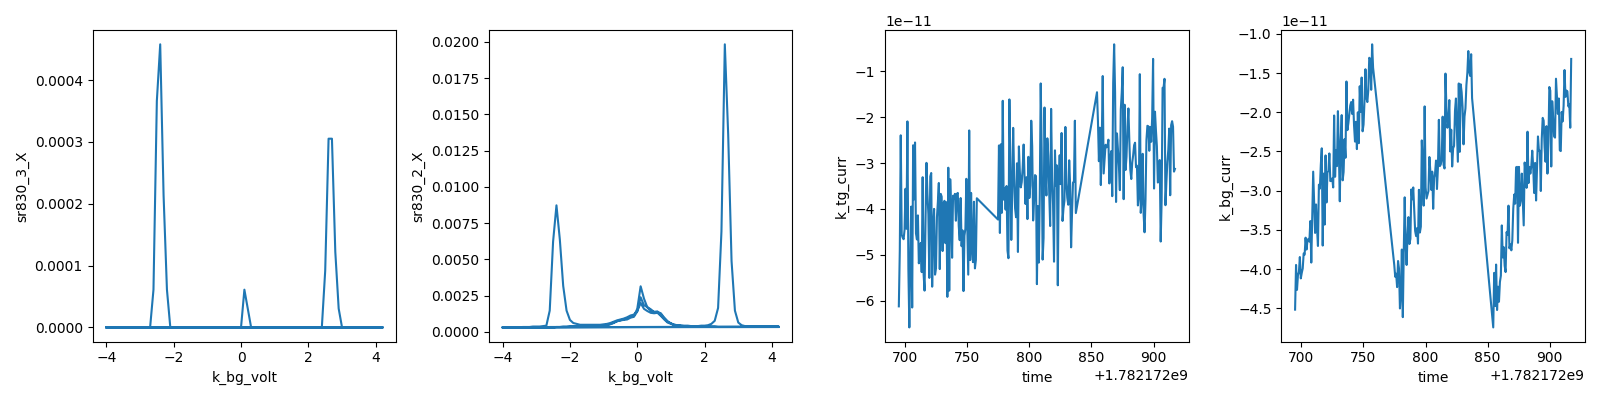

2026-06-22 17:01:57,815 [INFO] Completed in 0h 3m 44s
2026-06-22 17:01:57,816 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260622-zf1\data\1\data.tsv.gz
2026-06-22 17:01:57,878 [INFO] Ramping k_bg_volt: 4.2 -> 0.0
2026-06-22 17:02:03,214 [INFO] Ramping k_tg_volt: 3.0 -> 0.0


In [13]:
# === Step-1 reconnaissance: 3-row gatemap (TG slow {-3,0,+3}, BG fast) ===
# De-risks the full survey: CNP magnitude (-> map sensitivity), CNP-vs-TG slope
# (cap-ratio preview), per-point timing (-> map pricing), leakage/clipping check.
# Still pre-field (magnet pristine), per Step 1.

# --- precondition reads (state this cell assumes but does not set) ---
_T = temperature(); _B = magnet.field()
print(f"probe MC T = {_T*1e3:.1f} mK   (expect base)")
print(f"magnet B   = {_B*1e3:+.3f} mT  (expect ~0 — still pristine)")
print(f"k_tg.volt  = {k_tg.volt():+.4f} V   k_bg.volt = {k_bg.volt():+.4f} V")
assert _T < 0.060, f"T={_T*1e3:.1f} mK not at base"
assert abs(_B) < 0.005, f"|B|={_B*1e3:.2f} mT not ~0 (magnet should be pristine)"

# AC drive -> 1 nA; refresh meas_config so THIS run's metadata is correct.
sr830_1.amplitude(0.1)
meas_config["bias_voltage_1"] = sr830_1.amplitude()
meas_config["lockin_freq_1"]  = sr830_1.frequency()
meas_config["comment"] = "recon 3-row gatemap: TG{-3,0,+3}, BG -4..+4.2, 1nA, B=0"

# Print live lock-in settings (snapshot didn't capture them), then set voltage
# channels GENEROUS so the CNP peak can't clip during reconnaissance.
for lia in (sr830_1, sr830_2, sr830_3):
    print(f"{lia.name}: tc={lia.time_constant()} s  sens={lia.sensitivity()} V")
sr830_2.sensitivity(0.5)
sr830_3.sensitivity(0.5)
print("set sr830_2/3 sensitivity -> 0.5 V (recon, no-clip)")

s = sweep.AsyncStation(meas_config)
s.add_comment('gatemap')
s.add_comment('branch: Step-1 reconnaissance (3-row, de-risk full survey)')
s.add_comment('TG slow {-3,0,+3} V; BG fast -4 -> +4.2 V (83); B=0')

s.ramp(k_tg.volt, -3.0)
s.ramp(k_bg.volt, -4.0)

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for lia in (sr830_1, sr830_2, sr830_3):
    s.fp(lia.X).fp(lia.P)

s.plot(k_bg.volt, sr830_3.X)   # 4T Rxx (30-31)
s.plot(k_bg.volt, sr830_2.X)   # 2T (5-4)
s.plot('time', k_tg.curr)      # live leakage
s.plot('time', k_bg.curr)

try:
    s.megasweep(k_tg.volt, np.array([-3.0, 0.0, 3.0]),
                k_bg.volt, np.linspace(-4.0, 4.2, 83),
                slow_delay=2, fast_delay=0.5)
finally:
    s.ramp(k_bg.volt, 0.0)
    s.ramp(k_tg.volt, 0.0)


## HERA — Step-1 survey gatemap (full box, pristine field) + cap-ratio substrate

The recon de-risked this: cap-ratio **1.176 ≈ prior 1.18** ✓, timing **0.89 s/pt** (measured), CNP magnitudes known (4T ≤ 4.6 kΩ, 2T ≤ 198 kΩ), leakage clean. And the candidate region (D≈−0.5 V/nm, n≈−5×10¹¹ holes-into-TMD) is confirmed in-box at **Vtg≈−3.9, Vbg≈+2.7**.

This is the Step-1 survey — the densest pristine-field first-look, double duty as the `cnp-and-dline-calibration` substrate (105 CNP points → refined cap-ratio across the full TG range). **Magnet untouched** (B≈0) per the field-history protocol.

**Design:**
- **TG slow** `linspace(−7, +6, 105)` (0.125 V), **BG fast** `linspace(−4, +4.2, 83)` (0.1 V) — full validator box, corners included (coverage gate).
- **Swept TG −7→+6 deliberately** so the candidate region (Vtg≈−4 to −5) lands **early** — my checkpoint sits right in it.
- **Sensitivities** (autorange unusable — no-ops <160° phase, our channels ~0°): **sr830_3 (4T, candidate channel) → 5 mV** to resolve low Rxx to ~50 Ω (CNP clips at high D — acceptable, candidates are *away* from CNP); **sr830_2 (2T) → 0.5 V**, corner-safe, carries the CNP/cap-ratio.
- `slow_delay=2, fast_delay=0.5` (recon-validated). Gate currents fp'd + live-plotted for leakage.

**Cost: ~2.2 hr** (8715 pts × 0.89 s/pt, measured rate).

**Checkpoint @ ~row 30 (~35 min, ~28%)** — by then TG has covered the full candidate region. I read (via the armed `hera-watch` per-row digests): (1) a low-Rxx arc near Vtg≈−3.9, Vbg≈+2.7? (2) CNP ridge tracking the recon slope; (3) leakage < threshold; (4) sr830_3 not pathologically clipping in the candidate region. **Fork:** clean landscape → continue to full map; clear candidate already resolved → may abandon early and pivot to bias spectroscopy; leakage/clip problem → interrupt and adjust. An early call saves ~1.5 hr.


probe MC T = 33.7 mK   (expect base)
magnet B   = -0.008 mT  (expect ~0 — still pristine)
k_tg.volt  = +0.0000 V   k_bg.volt = +0.0000 V
sr830_1: tc=0.3 s  sens=0.001 V
sr830_2: tc=0.3 s  sens=0.5 V
sr830_3: tc=0.3 s  sens=0.005 V
2026-06-22 17:07:43,320 [INFO] Ramping k_tg_volt: 0.0 -> -7.0
2026-06-22 17:07:52,311 [INFO] Ramping k_bg_volt: 0.0 -> -4.0
2026-06-22 17:07:57,410 [INFO] Starting megasweep with ID 2
2026-06-22 17:07:57,411 [INFO] Minimum duration 1h 16m 7s


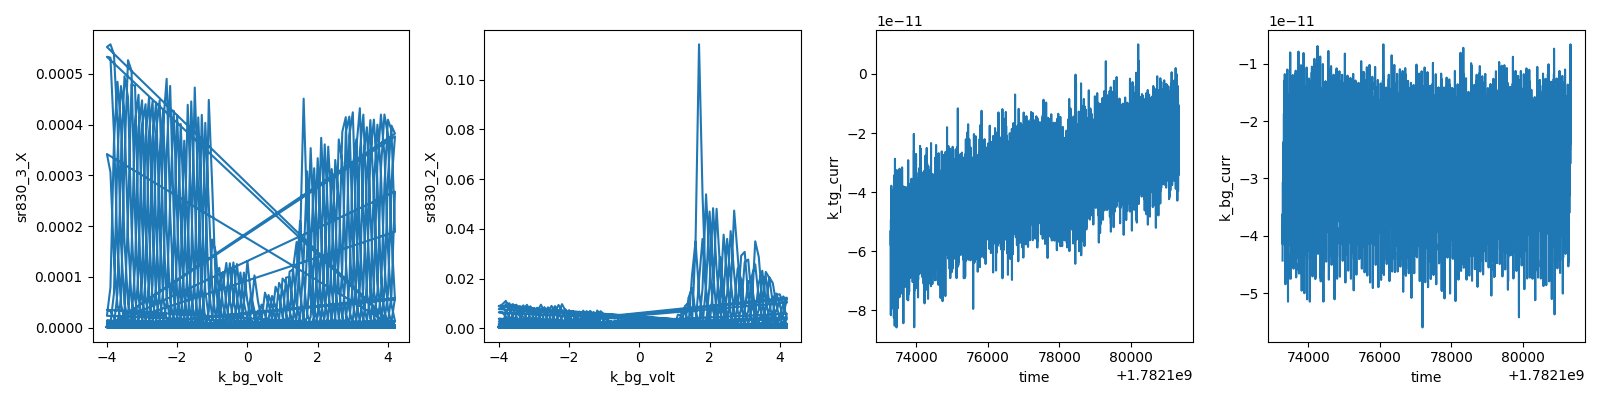

2026-06-22 19:22:15,951 [INFO] Completed in 2h 14m 17s
2026-06-22 19:22:15,951 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260622-zf1\data\2\data.tsv.gz
2026-06-22 19:22:16,014 [INFO] Ramping k_bg_volt: 4.2 -> 0.0
2026-06-22 19:22:21,353 [INFO] Ramping k_tg_volt: 6.0 -> 0.0


In [14]:
# === Step-1 survey gatemap: full validator box, pristine field ===
# TG slow (-7..+6, 105) x BG fast (-4..+4.2, 83). Doubles as cnp-and-dline
# cap-ratio substrate. Candidate region (Vtg~-3.9, Vbg~+2.7) lands EARLY
# (TG swept -7 -> +6) so the ~35 min checkpoint sits in it. Magnet pristine.

# --- precondition reads (state this cell assumes but does not set) ---
_T = temperature(); _B = magnet.field()
print(f"probe MC T = {_T*1e3:.1f} mK   (expect base)")
print(f"magnet B   = {_B*1e3:+.3f} mT  (expect ~0 — still pristine)")
print(f"k_tg.volt  = {k_tg.volt():+.4f} V   k_bg.volt = {k_bg.volt():+.4f} V")
assert _T < 0.060, f"T={_T*1e3:.1f} mK not at base"
assert abs(_B) < 0.005, f"|B|={_B*1e3:.2f} mT not ~0 (magnet should be pristine)"

# AC drive -> 1 nA; refresh meas_config so THIS run's metadata is correct.
sr830_1.amplitude(0.1)
meas_config["bias_voltage_1"] = sr830_1.amplitude()
meas_config["lockin_freq_1"]  = sr830_1.frequency()
meas_config["comment"] = "Step-1 survey gatemap: TG[-7,6]x BG[-4,4.2], 1nA, B=0"

# Sensitivities: 4T (sr830_3) -> 5 mV to resolve low-Rxx candidates (CNP clips
# at high D, acceptable); 2T (sr830_2) -> 0.5 V, corner-safe, carries CNP.
sr830_2.sensitivity(0.5)
sr830_3.sensitivity(0.005)
for lia in (sr830_1, sr830_2, sr830_3):
    print(f"{lia.name}: tc={lia.time_constant()} s  sens={lia.sensitivity()} V")

s = sweep.AsyncStation(meas_config)
s.add_comment('gatemap')
s.add_comment('Step-1 survey, full box; cap-ratio substrate (cnp-and-dline-calibration)')
s.add_comment('TG slow [-7,6] (105); BG fast [-4,4.2] (83); B=0; 1nA')

s.ramp(k_tg.volt, -7.0)
s.ramp(k_bg.volt, -4.0)

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for lia in (sr830_1, sr830_2, sr830_3):
    s.fp(lia.X).fp(lia.P)

s.plot(k_bg.volt, sr830_3.X)   # 4T Rxx (30-31) — candidate channel
s.plot(k_bg.volt, sr830_2.X)   # 2T (5-4)
s.plot('time', k_tg.curr)      # live leakage
s.plot('time', k_bg.curr)

try:
    s.megasweep(k_tg.volt, np.linspace(-7.0, 6.0, 105),
                k_bg.volt, np.linspace(-4.0, 4.2, 83),
                slow_delay=2, fast_delay=0.5)
finally:
    s.ramp(k_bg.volt, 0.0)
    s.ramp(k_tg.volt, 0.0)


## HERA — Run 3: fine constant-D n-linecuts (rule out an undersampled SC arc)

The survey found no candidate, but its n-resolution (BG step 0.1 V ≈ 0.83×10¹¹) is **coarser than the predicted arc width (~0.5×10¹¹)** — a narrow SC arc could have threaded between grid points. This is the decisive resolution check before any "not-SC" lean (investigation Step 1: "locate with linecuts first, n range wider than the nominal band").

**Four constant-D n-linecuts** at D = −0.35, −0.45, −0.55, −0.65 V/nm (bracketing the BBG/WSe₂ prior, both around and beyond D≈−0.5), each scanning **n = −1.5 → −9×10¹¹** (well wider than the nominal −4 to −6 band), **n-step 0.075×10¹¹ — ~11× finer than the survey**. 394 pts total; gate vectors precomputed from the confirmed calibration (c_bg/c_tg = 1.185) and clipped to validators by dropping out-of-box points (D=−0.65 line trimmed to 91 pts). Loaded from `hera_scratch/linecut_vectors.npz`; co-swept via `multisweep`.

- **Drive 1 nA** (consistent with the survey; SNR over fragile-state gentleness — the question here is *resolution*, not drive. A 0.5 nA recheck is a cheap follow-up if anything looks marginal).
- **sr830_3 → 2 mV** (resolve Rxx to ~few Ω; an SC dip to <5 Ω from the ~20 Ω metallic background is unmistakable), sr830_2 → 0.1 V. `delay=1.2` (3×tc, more averaging than the survey's 0.5).
- Magnet untouched (still nominal zero; ~2 mT trapped flux unchanged from the survey — the effective-zero-field hedge is for later field work).

**Preconditions** asserted: base T, B≈0. **Cost ~10 min.** **Read after:** any Rxx dip below the metallic background along any D-line → zoom + bias spectroscopy on it; all four flat at fine resolution → the undersampling hole is closed and I move to the field/effective-zero question and the calibrated call.


probe MC T = 33.7 mK   (expect base)
magnet B   = -0.026 mT  (expect ~0 nominal; ~2 mT trapped flux unchanged)
loaded 394 pts across D-lines [np.float64(-0.35), np.float64(-0.45), np.float64(-0.55), np.float64(-0.65)]
sr830_1: tc=0.3 s  sens=0.001 V
sr830_2: tc=0.3 s  sens=0.1 V
sr830_3: tc=0.3 s  sens=0.002 V
2026-06-22 19:33:46,069 [INFO] Ramping k_tg_volt: 0.0 -> -2.860094589521381
2026-06-22 19:33:49,772 [INFO] Ramping k_bg_volt: 0.0 -> 2.242857692496005
2026-06-22 19:33:52,588 [INFO] Starting multisweep with ID 3
2026-06-22 19:33:52,589 [INFO] Minimum duration 0h 7m 52s


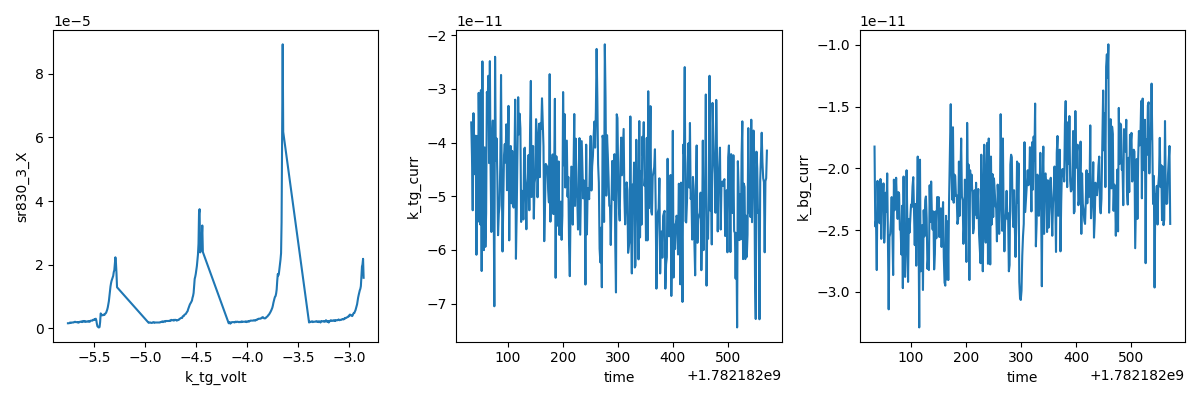

2026-06-22 19:42:51,961 [INFO] Completed in 0h 8m 58s
2026-06-22 19:42:51,963 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260622-zf1\data\3\data.tsv.gz
2026-06-22 19:42:52,024 [INFO] Ramping k_tg_volt: -5.754 -> 0.0
2026-06-22 19:42:59,422 [INFO] Ramping k_bg_volt: 3.7905 -> 0.0


In [15]:
# === Run 3: fine constant-D n-linecuts (rule out an undersampled SC arc) ===
# 4 D-lines (D=-0.35,-0.45,-0.55,-0.65), n=-1.5..-9e11, n-step 0.075e11 (~11x
# finer than the survey BG step). Gate vectors precomputed from the confirmed
# calibration (c_bg/c_tg=1.185), clipped by dropping out-of-box pts. Base T, B nominal-0.

# --- precondition reads (state this cell assumes but does not set) ---
_T = temperature(); _B = magnet.field()
print(f"probe MC T = {_T*1e3:.1f} mK   (expect base)")
print(f"magnet B   = {_B*1e3:+.3f} mT  (expect ~0 nominal; ~2 mT trapped flux unchanged)")
assert _T < 0.060, f"T={_T*1e3:.1f} mK not at base"
assert abs(_B) < 0.005, f"|B|={_B*1e3:.2f} mT not ~nominal-0"

# load precomputed constant-D vectors
_lc = np.load("hera_scratch/linecut_vectors.npz")
vtg_vec = _lc["vtg"]; vbg_vec = _lc["vbg"]
print(f"loaded {len(vtg_vec)} pts across D-lines {list(_lc['Ds'])}")
assert (vtg_vec>=-7.0).all() and (vtg_vec<=6.0).all(), "Vtg out of validator box"
assert (vbg_vec>=-4.0).all() and (vbg_vec<=4.2).all(), "Vbg out of validator box"

# AC drive -> 1 nA; refresh meas_config
sr830_1.amplitude(0.1)
meas_config["bias_voltage_1"] = sr830_1.amplitude()
meas_config["lockin_freq_1"]  = sr830_1.frequency()
meas_config["comment"] = "Run3 fine n-linecuts: D={-.35,-.45,-.55,-.65}, n=-1.5..-9e11, step .075e11, 1nA, B=0"

sr830_2.sensitivity(0.1)
sr830_3.sensitivity(0.002)
for lia in (sr830_1, sr830_2, sr830_3):
    print(f"{lia.name}: tc={lia.time_constant()} s  sens={lia.sensitivity()} V")

s = sweep.AsyncStation(meas_config)
s.add_comment('cnp-and-dline-calibration')   # constant-D lines designed off this recipe
s.add_comment('Run3 fine n-linecuts to rule out undersampled SC arc (sc-characterization Step 1)')
s.add_comment('D={-0.35,-0.45,-0.55,-0.65} V/nm; n=-1.5..-9e11; step 0.075e11; 1nA; B=0')

s.ramp(k_tg.volt, float(vtg_vec[0]))
s.ramp(k_bg.volt, float(vbg_vec[0]))

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for lia in (sr830_1, sr830_2, sr830_3):
    s.fp(lia.X).fp(lia.P)

s.plot(k_tg.volt, sr830_3.X)   # 4T Rxx — candidate channel
s.plot('time', k_tg.curr)      # live leakage
s.plot('time', k_bg.curr)

try:
    s.multisweep([k_tg.volt, k_bg.volt], [vtg_vec, vbg_vec], delay=1.2)
finally:
    s.ramp(k_tg.volt, 0.0)
    s.ramp(k_bg.volt, 0.0)


## HERA — Run 4: confirm the candidate + pin the optimum + resolve the floor

Run 3 found a **coherent SC-like Rxx dip** (26→2.4 Ω over ~7 points, resistive phase, steady current) at **n≈−4.8×10¹¹, D≈−0.65 V/nm** — in the BBG/WSe₂ proximity-SC window, on the D<0 side, on the most-negative D line only. The survey missed it (coarse n-step). This is a genuine candidate; this run nails it down before characterization.

Three things at once (one `multisweep`, 204 pts, ~7 min):
1. **Reproduce + resolve the floor.** Re-measure D=−0.65 with **sr830_3 → 200 µV** (resolution ~0.07 Ω vs the 2 mV run's ~0.7 Ω; the dip bottomed at the old floor). Tells us if Rxx→0 (SC-leaning) or floors finite (failed-SC / anomalous-metal fork).
2. **Pin the optimum D.** Fine constant-D linecuts at D = −0.55, −0.60, −0.65 (the in-box bracket — see below), n = −3.7 → −6.2, step 0.05×10¹¹.
3. **Probe the max-|D| boundary.** An **edge sweep** (BG pinned at +4.198 V, TG −4→−6) — because **D≈−0.65 is essentially the most-negative D reachable at this density**: D=−0.70/−0.75 would need BG>+4.2 V (validator cap). The candidate sits near the accessible-D edge; the edge sweep traces the boundary the way the coverage gate prescribes. If the dip is still deepening at the edge, the optimum is **instrument-limited** (a stated coverage caveat, not a free pass).

Drive 1 nA (consistent; bias spectroscopy will map Ic next). tc 0.3 s, delay 1.5 (≥5×tc, better low-R SNR). Magnet untouched. **Preconditions** asserted: base T, B≈0. **Read after:** the floor value (SC vs failed-SC lean), the optimum (n,D) → that becomes the operating point for **bias spectroscopy** (the critical-current hallmark, the decisive next measurement).


probe MC T = 33.7 mK   (expect base)
magnet B   = -0.017 mT  (expect ~0 nominal)
loaded 204 pts (segments: [np.str_('D=-0.55'), np.str_('D=-0.60'), np.str_('D=-0.65'), np.str_('edge')])
sr830_1: tc=0.3 s  sens=0.001 V
sr830_2: tc=0.3 s  sens=0.1 V
sr830_3: tc=0.3 s  sens=0.0002 V
2026-06-22 19:49:38,667 [INFO] Ramping k_tg_volt: 0.0 -> -4.590011098597185
2026-06-22 19:49:44,582 [INFO] Ramping k_bg_volt: 0.0 -> 3.4434934192679227
2026-06-22 19:49:48,911 [INFO] Starting multisweep with ID 4
2026-06-22 19:49:48,912 [INFO] Minimum duration 0h 5m 6s


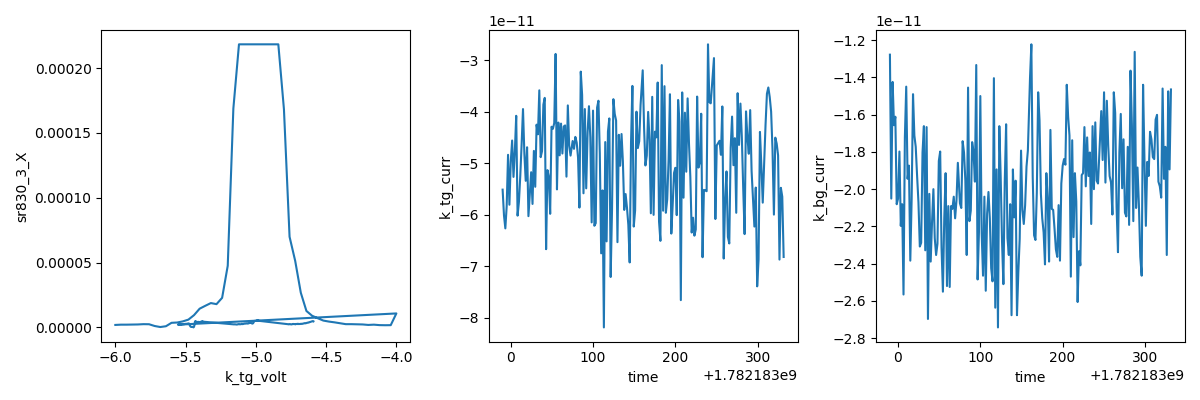

2026-06-22 19:55:32,130 [INFO] Completed in 0h 5m 42s
2026-06-22 19:55:32,130 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260622-zf1\data\4\data.tsv.gz
2026-06-22 19:55:32,198 [INFO] Ramping k_tg_volt: -6.0 -> 0.0
2026-06-22 19:55:40,091 [INFO] Ramping k_bg_volt: 4.198 -> 0.0


In [16]:
# === Run 4: confirm candidate + pin optimum D + resolve Rxx floor ===
# 3 fine constant-D linecuts (D=-0.55,-0.60,-0.65, in-box bracket) + an edge
# sweep (BG=+4.198 pinned, TG -4..-6) probing the max-|D| boundary. sr830_3 at
# 200 uV to resolve whether Rxx->0. Base T, B nominal-0. (Run 3 found the dip.)

# --- precondition reads ---
_T = temperature(); _B = magnet.field()
print(f"probe MC T = {_T*1e3:.1f} mK   (expect base)")
print(f"magnet B   = {_B*1e3:+.3f} mT  (expect ~0 nominal)")
assert _T < 0.060, f"T={_T*1e3:.1f} mK not at base"
assert abs(_B) < 0.005, f"|B|={_B*1e3:.2f} mT not ~nominal-0"

_v = np.load("hera_scratch/confirm_vectors.npz")
vtg_vec = _v["vtg"]; vbg_vec = _v["vbg"]
print(f"loaded {len(vtg_vec)} pts (segments: {sorted(set(_v['seg']))})")
assert (vtg_vec>=-7.0).all() and (vtg_vec<=6.0).all(), "Vtg out of box"
assert (vbg_vec>=-4.0).all() and (vbg_vec<=4.2).all(), "Vbg out of box"

sr830_1.amplitude(0.1)
meas_config["bias_voltage_1"] = sr830_1.amplitude()
meas_config["lockin_freq_1"]  = sr830_1.frequency()
meas_config["comment"] = "Run4 confirm candidate: D={-.55,-.60,-.65}+edge(BG+4.198), n~-4.8 dip, 1nA, 200uV, B=0"

sr830_2.sensitivity(0.1)
sr830_3.sensitivity(2e-4)            # 200 uV -> resolve Rxx floor (~0.07 Ohm)
sr830_3.time_constant(0.3)
for lia in (sr830_1, sr830_2, sr830_3):
    print(f"{lia.name}: tc={lia.time_constant()} s  sens={lia.sensitivity()} V")

s = sweep.AsyncStation(meas_config)
s.add_comment('cnp-and-dline-calibration')   # constant-D gate linecuts
s.add_comment('Run4 candidate confirm: fine D-linecuts {-0.55,-0.60,-0.65}/nm + max-|D| edge sweep')
s.add_comment('dip from run3 at n~-4.8e11, D~-0.65; sr830_3 @ 200uV to resolve floor; 1nA; B=0')

s.ramp(k_tg.volt, float(vtg_vec[0]))
s.ramp(k_bg.volt, float(vbg_vec[0]))

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for lia in (sr830_1, sr830_2, sr830_3):
    s.fp(lia.X).fp(lia.P)

s.plot(k_tg.volt, sr830_3.X)
s.plot('time', k_tg.curr)
s.plot('time', k_bg.curr)

try:
    s.multisweep([k_tg.volt, k_bg.volt], [vtg_vec, vbg_vec], delay=1.5)
finally:
    s.ramp(k_tg.volt, 0.0)
    s.ramp(k_bg.volt, 0.0)


## HERA — Run 5: bias spectroscopy at the optimum — the critical-current test

Run 4 confirmed **Rxx → ~0** (min 0.52 Ω, X-offset-limited) at **n≈−4.65×10¹¹, D≈−0.65 V/nm** (Vtg=−5.444, Vbg=+4.053) — first SC hallmark in hand. This is the decisive nonlinear test (`bias-spectroscopy`): does the zero-resistance state carry a **supercurrent** (dV/dI≈0 below a critical current Ic, rising at Ic), or is it just a good low-R metal (ohmic dV/dI, no lobe)?

**Design:**
- Gates fixed at the optimum; **DC bias swept −15 → +15 V** via `dc205_1` through the 100 MΩ resistor → **Idc −150 → +150 nA**, symmetric across 0 (captures Ic⁻ and Ic⁺). This is the wide bracket the investigation asks for (reference Ic ~20 nA [s41586-022-05446-x]; real devices run several× higher; ±150 nA is the full dc205 range).
- **Step 0.0987 V (≈1 nA), 305 pts — deliberately ≤0.1 V** to avoid the DC205's mandatory 10 s settle (rig card); ~13 min total.
- AC sense **1 nA** (≪ expected Ic), sr830_3 @ 200 µV, tc 0.3 s, delay 1.5 s (≥5×tc). dV/dI = (sr830_3_X/100)/(sr830_1_X/−1e6).
- Magnet untouched (B≈0).

**Preconditions** asserted: base T, B≈0; gates ramped to optimum then verified. dc205 parked to 0 in `finally` (device-card rule), gates parked after.

**Read after:** a flat dV/dI≈0 plateau below |Ic| rising to the normal value = **supercurrent → SC** (then field-kill + T-dependence to complete the constellation). Ohmic dV/dI with no lobe = good metal, not SC. A smooth/smeared onset → reduce AC drive or check heating. Note the QAH confound needs an Rxy read (no transverse pair in the current config — a follow-up); the field-kill test is the cleaner B=0 discriminator next.


probe MC T = 33.7 mK   (expect base)
magnet B   = -0.008 mT  (expect ~0 nominal)
optimum gates: Vtg=-5.4443 Vbg=+4.0529
DC bias: 305 pts, Idc -150..+150 nA, step 0.0987 V
2026-06-22 20:00:05,905 [INFO] Ramping k_tg_volt: 0.0 -> -5.444293227516282
2026-06-22 20:00:12,909 [INFO] Ramping k_bg_volt: 0.0 -> 4.052858846737615
2026-06-22 20:00:18,022 [INFO] Ramping dc205_1_voltage: 0.0 -> -15.0
gates set: Vtg=-5.4445 Vbg=+4.0530
2026-06-22 20:00:22,824 [INFO] Starting sweep with ID 5
2026-06-22 20:00:22,824 [INFO] Minimum duration 0h 7m 37s


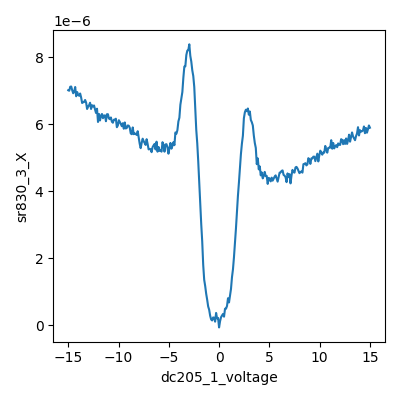

2026-06-22 20:08:52,401 [INFO] Completed in 0h 8m 29s
2026-06-22 20:08:52,401 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260622-zf1\data\5\data.tsv.gz
2026-06-22 20:08:52,411 [INFO] Ramping dc205_1_voltage: 15.0 -> 0.0
2026-06-22 20:08:56,869 [INFO] Ramping k_tg_volt: -5.4445 -> 0.0
2026-06-22 20:09:03,875 [INFO] Ramping k_bg_volt: 4.053 -> 0.0


In [17]:
# === Run 5: bias spectroscopy (dV/dI vs Idc) at the SC candidate optimum ===
# Gates fixed at n=-4.65e11, D=-0.65 (Vtg=-5.444, Vbg=+4.053). DC bias swept
# +/-15V (=+/-150nA via 100MOhm), step <=0.1V to avoid the DC205 10s settle.
# Looking for a critical-current lobe: dV/dI~0 below Ic, rising at Ic.

# --- precondition reads ---
_T = temperature(); _B = magnet.field()
print(f"probe MC T = {_T*1e3:.1f} mK   (expect base)")
print(f"magnet B   = {_B*1e3:+.3f} mT  (expect ~0 nominal)")
assert _T < 0.060, f"T={_T*1e3:.1f} mK not at base"
assert abs(_B) < 0.005, f"|B|={_B*1e3:.2f} mT not ~nominal-0"

_pt = np.load("hera_scratch/bias_pt.npz"); VTG_OPT=float(_pt["vtg"]); VBG_OPT=float(_pt["vbg"])
print(f"optimum gates: Vtg={VTG_OPT:+.4f} Vbg={VBG_OPT:+.4f}")
assert -7.0<=VTG_OPT<=6.0 and -4.0<=VBG_OPT<=4.2, "optimum out of validator box"

sr830_1.amplitude(0.1)                       # 1 nA AC sense (<< expected Ic)
meas_config["bias_voltage_1"] = sr830_1.amplitude()
meas_config["lockin_freq_1"]  = sr830_1.frequency()
meas_config["comment"] = "Run5 bias-spec: dV/dI vs Idc at n=-4.65e11/D=-0.65, Idc +/-150nA, 1nA AC, B=0"

sr830_2.sensitivity(0.1); sr830_3.sensitivity(2e-4); sr830_3.time_constant(0.3)

Vdc_vec = np.linspace(-15.0, 15.0, 305)      # step ~0.0987V (<0.1 -> no 10s DC205 settle); Idc=Vdc/1e8
print(f"DC bias: {len(Vdc_vec)} pts, Idc {Vdc_vec[0]/1e8*1e9:+.0f}..{Vdc_vec[-1]/1e8*1e9:+.0f} nA, step {abs(Vdc_vec[1]-Vdc_vec[0]):.4f} V")

s = sweep.AsyncStation(meas_config)
s.add_comment('bias-spectroscopy')
s.add_comment('Run5 dV/dI vs Idc point check at SC candidate optimum')
s.add_comment('gates: Vtg=-5.444 Vbg=+4.053 (n=-4.65e11, D=-0.65); Idc +/-150nA; 1nA AC; B=0')

# ramp gates to optimum, settle; start DC at one extreme
s.ramp(k_tg.volt, VTG_OPT)
s.ramp(k_bg.volt, VBG_OPT)
s.ramp(dc205_1.volt, float(Vdc_vec[0]))
print(f"gates set: Vtg={k_tg.volt():+.4f} Vbg={k_bg.volt():+.4f}")

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(dc205_1.volt)
for lia in (sr830_1, sr830_2, sr830_3):
    s.fp(lia.X).fp(lia.P)

s.plot(dc205_1.volt, sr830_3.X)   # dV/dI vs Idc (4T)

try:
    s.sweep(dc205_1.volt, Vdc_vec, delay=1.5)
finally:
    s.ramp(dc205_1.volt, 0.0)     # device-card rule: dc205 -> 0 before ending
    s.ramp(k_tg.volt, 0.0)
    s.ramp(k_bg.volt, 0.0)


## HERA — Run 6: field response (B⊥ kill / B_c⊥) at the SC optimum — first magnet energization

Supercurrent confirmed (Ic≈18 nA). Now the field hallmark (`field-sweep-1d`, investigation Step 3): does a small B⊥ quench the zero-resistance state **while the normal state stays ≈ unchanged** (the field-kill that counts *strong* for SC), and what is B_c⊥?

**First field energization this session** — applying the brief's field discipline:
- **One-sided, monotonic toward 0:** position-ramp 0 → **+80 mT** (well into expected normal state, inside the 100 mT cap), settle, then **sweep +80 mT → 0** (decreasing |B|, never crossing 0). The −B side and an effective-zero zoom are follow-ups.
- **Settle 120 s** after the positioning ramp (ramp-heating is largest at low |B| — rig card); T is fp'd densely so I can verify base-T recovery post-hoc and *derive the real settle for later ramps* (none measured yet this session).
- **Measured field recorded:** fp `magnet.field` (readback) alongside the setpoint — after an 80 mT excursion, nominal 0 carries up to ~10 mT remanence, so the true-field axis matters.

At the optimum (Vtg=−5.444, Vbg=+4.053), **1 nA AC, zero DC bias** (so Rxx≈0 while Ic>1 nA; Rxx rises toward normal once B suppresses Ic below the probe). 161 pts (0.5 mT), delay 1.

**Preconditions** asserted: base T, B≈0 start; prints `magnet.ramp_rate()`. **Cost ~6–8 min.** **Read after:** Rxx rising from ~0 at low B to a **flat normal plateau (~55 Ω, matching run 5)** = field-kill confirmed + B_c⊥ estimate (where Rxx ≈ half-normal). A sloping/non-saturating high-B Rxx = generic MR caveat. If Rxx hasn't saturated by 80 mT, B_c⊥ > 80 mT (note ξ ≲ 60 nm) — escalate toward the cap.


probe MC T = 33.7 mK   (expect base)
magnet B   = -0.023 mT  (expect ~0 start)
magnet ramp_rate = 0.001 T/s
2026-06-22 20:24:50,905 [INFO] Ramping k_tg_volt: 0.0 -> -5.444293227516282
2026-06-22 20:24:57,909 [INFO] Ramping k_bg_volt: 0.0 -> 4.052858846737615
2026-06-22 20:25:03,020 [INFO] Ramping dc205_1_voltage: 0.0 -> 0.0
after +80mT ramp + 120s settle: T = 33.7 mK, B = +80.00 mT
2026-06-22 20:28:30,838 [INFO] Starting sweep with ID 6
2026-06-22 20:28:30,839 [INFO] Minimum duration 0h 2m 41s


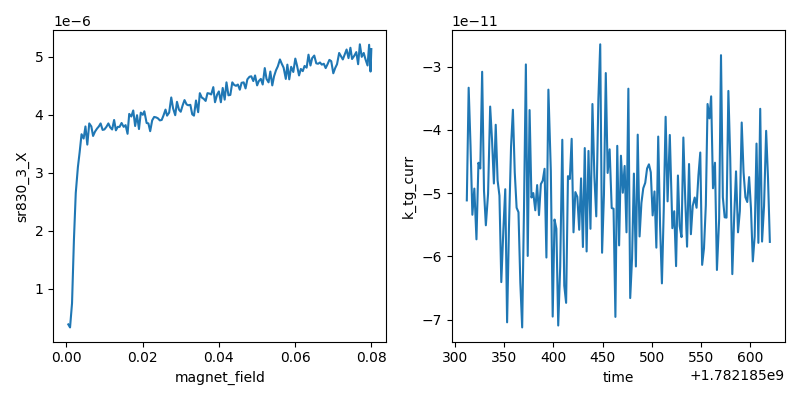

2026-06-22 20:33:40,289 [INFO] Completed in 0h 5m 9s
2026-06-22 20:33:40,290 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260622-zf1\data\6\data.tsv.gz
2026-06-22 20:33:40,497 [INFO] Ramping dc205_1_voltage: 0.0 -> 0.0
2026-06-22 20:33:40,559 [INFO] Ramping k_tg_volt: -5.4445 -> 0.0
2026-06-22 20:33:47,566 [INFO] Ramping k_bg_volt: 4.053 -> 0.0


In [18]:
# === Run 6: field response (B_perp kill / B_c) at the SC optimum ===
# First magnet energization this session. One-sided sweep +80mT -> 0 (toward 0,
# never crossing). 1nA AC, zero DC bias, at n=-4.65e11/D=-0.65. Field discipline:
# settle after positioning ramp; record measured field; T fp'd to derive settle.

# --- precondition reads ---
_T = temperature(); _B = magnet.field(); _rr = magnet.ramp_rate()
print(f"probe MC T = {_T*1e3:.1f} mK   (expect base)")
print(f"magnet B   = {_B*1e3:+.3f} mT  (expect ~0 start)")
print(f"magnet ramp_rate = {_rr} T/s")
assert _T < 0.060, f"T={_T*1e3:.1f} mK not at base"
assert abs(_B) < 0.005, f"|B|={_B*1e3:.2f} mT not ~0 at start"

_pt = np.load("hera_scratch/bias_pt.npz"); VTG_OPT=float(_pt["vtg"]); VBG_OPT=float(_pt["vbg"])
assert -7.0<=VTG_OPT<=6.0 and -4.0<=VBG_OPT<=4.2

sr830_1.amplitude(0.1)
meas_config["bias_voltage_1"] = sr830_1.amplitude()
meas_config["lockin_freq_1"]  = sr830_1.frequency()
meas_config["comment"] = "Run6 field-kill: Rxx(B) +80mT->0 at n=-4.65e11/D=-0.65, 1nA AC, Vdc=0"
sr830_2.sensitivity(0.1); sr830_3.sensitivity(2e-4); sr830_3.time_constant(0.3)

s = sweep.AsyncStation(meas_config)
s.add_comment('field-sweep-1d')
s.add_comment('Run6 field-kill at SC optimum: Rxx(B) +80mT->0, 1nA AC, Vdc=0')
s.add_comment('label: (Vtg, Vbg) = (-5.4443, +4.0529); n=-4.65e11, D=-0.65')

# set operating point, zero DC bias
s.ramp(k_tg.volt, VTG_OPT)
s.ramp(k_bg.volt, VBG_OPT)
s.ramp(dc205_1.volt, 0.0)

s.fp(temperature)
s.fp(magnet.field)                  # measured field readback (vs setpoint axis)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for lia in (sr830_1, sr830_2, sr830_3):
    s.fp(lia.X).fp(lia.P)

s.plot(magnet.field, sr830_3.X)     # live Rxx(B)
s.plot('time', k_tg.curr)

# position to +80 mT (blocks until holding), settle, verify T, then sweep toward 0
magnet.field(0.080)
import time as _t; _t.sleep(120)
print(f"after +80mT ramp + 120s settle: T = {temperature()*1e3:.1f} mK, B = {magnet.field()*1e3:+.2f} mT")

try:
    s.sweep(magnet.field, np.linspace(0.080, 0.0, 161), delay=1)
finally:
    magnet.field(0.0)
    s.ramp(dc205_1.volt, 0.0)
    s.ramp(k_tg.volt, 0.0)
    s.ramp(k_bg.volt, 0.0)


## HERA — Run 7: T-dependence — Ic(T), the final hallmark (heat up LAST)

Four hallmarks in hand (Rxx→0, Ic≈18 nA lobe, reference Ic, field-kill B_c⊥≈2.5 mT/flat normal) → strong SC. This is the decisive thermal test: **Ic(T)** — the supercurrent lobe should melt continuously to Ic→0 at Tc. I chose the bias×T map over plain Rxx(T) because watching the dV/dI lobe collapse is the definitive "supercurrent melts at Tc" (and gives Ic(T) for the writeup), at only ~2 min/step over Rxx(T).

**Design (heater discipline — first heater use this session):**
- **Stepped warm-up** to 6 V (~423 mK) in 1 V increments with 60 s holds, then 300 s equilibration (device-card rule: ≤1 V steps, no thermal shock). Heater current printed to confirm it draws (open-line check).
- **Measure while cooling:** `megasweep` slow = `heater.volt` **6→0 V (11 steps)**, `slow_delay=300 s` thermalization per step; fast = `dc205_1.volt` ±3 V (**Idc ±30 nA**, 63 pts, step <0.1 V so no DC205 10 s settle). T read back from the `T` column (heater V is uncalibrated; approx 423→30 mK).
- Gates fixed at the optimum, field at nominal 0 (effective-zero region), 1 nA AC. fp `temperature`, `heater.volt`, `heater.curr`, `magnet.field`, gates, lock-ins.

**Cost ~85 min** + ~1 h re-cool afterward. **Checkpoint @ ~35 min** (via the armed `hera-watch` + a TSV T-read): confirm T descending monotonically, heater drawing current, and the dV/dI lobe beginning to appear as T drops — continue / adjust thermalization / abort.

**Preconditions** asserted: base T start, gates/field in place. `finally`: heater→0 (start re-cool), dc205→0, gates→0. **Read after:** Ic vs T → Tc (where Ic→0; %-of-normal / threshold convention, stated). If Ic is already 0 at the 423 mK top, Tc<423 mK (captured); if Ic still finite at the top, Tc>423 mK — note and extend toward the 6.5 V ceiling.


probe MC T = 33.7 mK (expect base)
magnet B   = -0.008 mT (nominal-0, effective-zero region)
2026-06-22 21:48:02,328 [INFO] Ramping k_tg_volt: 0.0 -> -5.444293227516282
2026-06-22 21:48:09,331 [INFO] Ramping k_bg_volt: 0.0 -> 4.052858846737615
2026-06-22 21:48:14,438 [INFO] Ramping dc205_1_voltage: 0.0 -> 0.0
2026-06-22 21:48:14,502 [INFO] Ramping heater_volt: 0.0 -> 1.0
2026-06-22 21:49:15,812 [INFO] Ramping heater_volt: 1.0 -> 2.0
2026-06-22 21:50:17,124 [INFO] Ramping heater_volt: 2.0 -> 3.0
2026-06-22 21:51:18,444 [INFO] Ramping heater_volt: 3.0 -> 4.0
2026-06-22 21:52:19,779 [INFO] Ramping heater_volt: 4.0 -> 5.0
2026-06-22 21:53:21,118 [INFO] Ramping heater_volt: 5.0 -> 6.0
warmed: heater.volt=6.00 V, heater.curr=617.94 uA, T=34 mK
2026-06-22 21:59:22,582 [INFO] Starting megasweep with ID 7
2026-06-22 21:59:22,582 [INFO] Minimum duration 1h 6m 33s


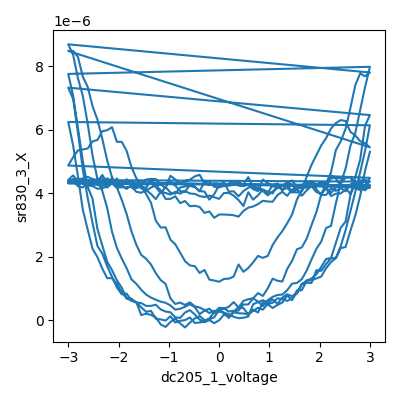

2026-06-22 23:08:33,240 [INFO] Completed in 1h 9m 10s
2026-06-22 23:08:33,241 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260622-zf1\data\7\data.tsv.gz
2026-06-22 23:08:33,306 [INFO] Ramping heater_volt: 0.0 -> 0.0
2026-06-22 23:08:33,314 [INFO] Ramping dc205_1_voltage: 3.0 -> 0.0
2026-06-22 23:08:34,221 [INFO] Ramping k_tg_volt: -5.4445 -> 0.0
2026-06-22 23:08:41,227 [INFO] Ramping k_bg_volt: 4.053 -> 0.0


In [19]:
# === Run 7: T-dependence — Ic(T) bias×T map (heat up LAST) ===
# slow = heater.volt 6->0 (measure while cooling), fast = dc205 bias +/-30nA.
# Gives Ic(T) -> Tc. First heater use: stepped warm-up, per-step thermalization,
# heater.curr verified. Gates at optimum, field nominal-0, 1nA AC.
import time as _t

# --- precondition reads ---
_T = temperature(); _B = magnet.field()
print(f"probe MC T = {_T*1e3:.1f} mK (expect base)")
print(f"magnet B   = {_B*1e3:+.3f} mT (nominal-0, effective-zero region)")
assert _T < 0.060, f"T={_T*1e3:.1f} mK not at base"
assert abs(_B) < 0.010, f"|B|={_B*1e3:.2f} mT not near 0"
_pt = np.load("hera_scratch/bias_pt.npz"); VTG_OPT=float(_pt["vtg"]); VBG_OPT=float(_pt["vbg"])

sr830_1.amplitude(0.1)
meas_config["bias_voltage_1"] = sr830_1.amplitude()
meas_config["lockin_freq_1"]  = sr830_1.frequency()
meas_config["comment"] = "Run7 T-dep Ic(T): heater 6->0V, dc205 +/-30nA, opt n=-4.65e11/D=-0.65, B~0"
sr830_2.sensitivity(0.1); sr830_3.sensitivity(2e-4); sr830_3.time_constant(0.3)

Vdc_fast = np.linspace(-3.0, 3.0, 63)         # Idc +/-30nA, step <0.1V (no DC205 10s settle)
h_down   = np.linspace(6.0, 0.0, 11)          # heater V, measure while cooling

s = sweep.AsyncStation(meas_config)
s.add_comment('temperature-dependence')
s.add_comment('Run7 Ic(T): slow heater 6->0V (measure cooling), fast dc205 +/-30nA at SC optimum')
s.add_comment('axis: heater 0-6V; (Vtg,Vbg)=(-5.4443,+4.0529) n=-4.65e11 D=-0.65; B~0; 1nA AC')

# set operating point + zero bias
s.ramp(k_tg.volt, VTG_OPT); s.ramp(k_bg.volt, VBG_OPT); s.ramp(dc205_1.volt, 0.0)

s.fp(temperature)
s.fp(heater.volt).fp(heater.curr)
s.fp(magnet.field)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(dc205_1.volt)
for lia in (sr830_1, sr830_2, sr830_3):
    s.fp(lia.X).fp(lia.P)

s.plot(dc205_1.volt, sr830_3.X)

# --- stepped warm-up to 6V (<=1V steps, holds), then equilibrate (device-card rule) ---
for hv in (1.0, 2.0, 3.0, 4.0, 5.0, 6.0):
    s.ramp(heater.volt, hv); _t.sleep(60)
_t.sleep(300)
print(f"warmed: heater.volt={heater.volt():.2f} V, heater.curr={heater.curr()*1e6:.2f} uA, T={temperature()*1e3:.0f} mK")
assert abs(heater.curr()) > 1e-7, "heater drawing ~no current — open line? abort"

try:
    s.megasweep(heater.volt, h_down,
                dc205_1.volt, Vdc_fast,
                slow_delay=300, fast_delay=1)
finally:
    s.ramp(heater.volt, 0.0)      # start re-cool
    s.ramp(dc205_1.volt, 0.0)
    s.ramp(k_tg.volt, 0.0)
    s.ramp(k_bg.volt, 0.0)
